# SBO Cloud and dust event Observations 
This is the script for plotting the example events used in Haberstock et al. 2026 (submitted to AMT) measured at Sonnblick Observatory (SBO, Austria). \
The cloud event represents a liquid cloud measured in the night of the 11.-12. August 2024; the dust event represents a saharan dust event measured on the 16. August 2024.
This script provides an overview plot as well as the size distributions for both events.

It uses the following datasets: 
- dust_overview.csv
- cloud_overview.csv
- cloudevents.csv (start and stop times of all cloud events during the campaign)
- fm_size_distribution.csv
- gfas_loss_corrected.csv
- gfas_pbp_polarzation.csv
- gfas_uncorrected.csv
all datasets are part of the dataset XX to be downloaded at Bolin Centre (link will follow soon)

Input needed: path of the data

Output
- Overview plot
- size distribution plot

author: Lea Haberstock, Stockholm University, Department of Environmental Science, Atmospheric Unit \
developed toether with: Darrel Baumgardner and Paul Zieger

contact: lea.haberstock@aces.su.se \
used in publication: Haberstock et al. 2026 (submitted to AMT) 

In [1]:
import sys  
import numpy as np
import pandas as pd
import glob2
import glob, os
import os
import datetime as dt
import calendar
from scipy.ndimage import shift
import scipy
from matplotlib.pyplot import figure
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.colors as colors
import matplotlib.ticker as ticker
import matplotlib as mpl


## Read in datasets

In [4]:
path = '/share/Lea/data/Paper1/Level_2/'
cloud_overview = pd.read_csv(path+'Other_field/cloud_event.csv',index_col=0,parse_dates=True)
dust_overview = pd.read_csv(path+'Other_field/dust_event.csv',index_col=0,parse_dates=True)
gfas_loss_corrected = pd.read_csv(path+'GFAS_field/dndD_corr.csv',index_col=0,parse_dates=True)

r_pol = pd.read_csv(path+'GFAS_field/r_pol_1hz.csv',index_col=0,parse_dates=True)
gfas_uncorrected = pd.read_csv(path+'GFAS_field/dndD.csv',index_col=0,parse_dates=True)
cloudevents = pd.read_csv('cloudevents.csv',index_col=0,parse_dates=True)
fm = pd.read_csv(path+'Other_field/fm_dndD.csv',index_col=0,parse_dates=True)

/tmp/ipykernel_3928839/827121520.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  cloudevents = pd.read_csv('cloudevents.csv',index_col=0,parse_dates=True)


In [5]:
gfas_loss_corrected = gfas_loss_corrected.resample('5min').mean()
gfas_uncorrected = gfas_uncorrected.resample('5min').mean()

In [6]:
cloudevents['Start'] = pd.to_datetime(cloudevents['Start']).dt.strftime('%Y-%m-%d %H:%M:%S')
cloudevents['End'] = pd.to_datetime(cloudevents['End']).dt.strftime('%Y-%m-%d %H:%M:%S')


In [7]:
optical_props = cloud_overview[['Scattering_Coeff_450', 'Scattering_Coeff_525','Scattering_Coeff_635', 'Single_Scattering_Albedo']].dropna()
optical_props_dust = dust_overview[['Scattering_Coeff_450', 'Scattering_Coeff_525','Scattering_Coeff_635', 'Single_Scattering_Albedo']].dropna()

### plotting prep

In [8]:
mpl.rcParams.update({
    "font.size": 12,          # base size
    "axes.titlesize": 12,
    "axes.labelsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
})

In [9]:
cloudevents[8:].iterrows()

<generator object DataFrame.iterrows at 0x7f4c5f421cf0>

In [10]:
start = pd.to_datetime('2024-08-11 15:00:00')
end = pd.to_datetime('2024-08-12 06:00:00')
start2 = pd.to_datetime('2024-08-16 00:00:00')
end2 = pd.to_datetime('2024-08-16 18:00:00')

# build a meshgrid for plotting polarization
x = pd.to_datetime(r_pol.loc[start:end].index).to_numpy(dtype="datetime64[ns]")
y = r_pol.loc[start:end].columns.to_numpy(dtype=float)
Z = r_pol.loc[start:end].to_numpy(dtype=float).T
X,Y = np.meshgrid(x,y)

u = pd.to_datetime(r_pol.loc[start2:end2].index).to_numpy(dtype="datetime64[ns]")
v = r_pol.loc[start2:end2].columns.to_numpy(dtype=float)
W = r_pol.loc[start2:end2].to_numpy(dtype=float).T
U,V = np.meshgrid(u,v)

params_s   = ['Scattering_Coeff_450', 'Scattering_Coeff_525', 'Scattering_Coeff_635']
l_s = ['450', '525', '635', ]
wl_color_s = ['blue','green','red']


### Overview plot

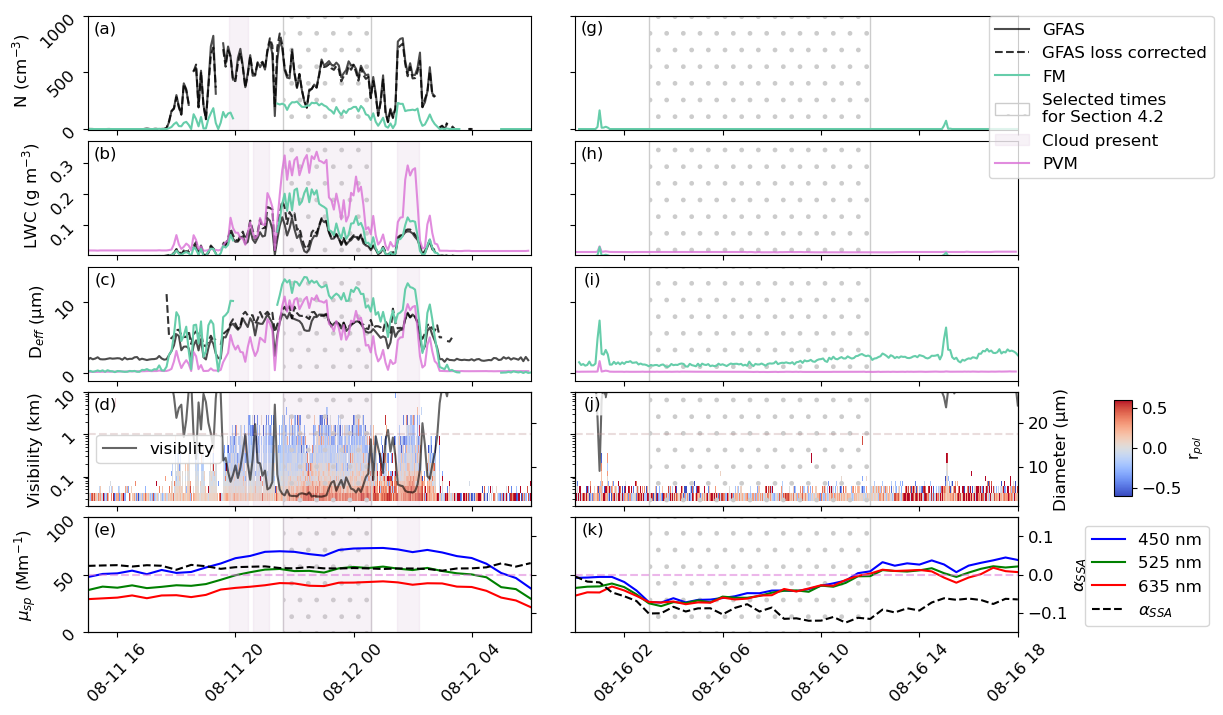

In [11]:
fig, ax = plt.subplots(5,2, figsize=(12,8))
ax = ax.flatten()
#GFAS
ax[0].plot(gfas_uncorrected.index,gfas_uncorrected['N'],color='black',alpha = 0.7,label='GFAS') 
ax[2].plot(gfas_uncorrected.index,gfas_uncorrected['LWC'],color='black',alpha = 0.7) 
ax[4].plot(gfas_uncorrected.index,gfas_uncorrected['D_eff'],color='black',alpha = 0.7,label='GFAS')

# GFAS loss-corrected
ax[0].plot(gfas_loss_corrected.index,gfas_loss_corrected['N'],color='black',linestyle = '--', alpha = 0.8,label='GFAS loss corrected')
ax[2].plot(gfas_loss_corrected.index,gfas_loss_corrected['LWC'],color='black',linestyle = '--', alpha = 0.8)
ax[4].plot(gfas_loss_corrected.index,gfas_loss_corrected['ED'],color='black',linestyle = '--', alpha = 0.8,label='GFAS loss corrected')

# PVM
ax[4].plot(cloud_overview.index,cloud_overview['PVM_D_eff'],color='orchid',alpha = 0.8,label='PVM')
ax[2].plot(cloud_overview.index,cloud_overview['PVM_LWC'],color='orchid',alpha = 0.8,label='PVM')

#FM
ax[0].plot(cloud_overview.index,cloud_overview['FM_N'],color='mediumaquamarine')
ax[4].plot(cloud_overview.index,cloud_overview['FM_D_eff'],color='mediumaquamarine')
ax[2].plot(cloud_overview.index,cloud_overview['FM_LWC'],color='mediumaquamarine')

#visibility
ax[6].plot((cloud_overview['Visibility']) ,c = 'k', label='visiblity', alpha = 0.6)
ax[6].axhline(y=1, color='rosybrown', linestyle='--', alpha = 0.3, )

# pbp polarization
ax6 = ax[6].twinx()
b = ax6.pcolormesh(X,Y,Z,cmap ='coolwarm', vmin = -0.6, vmax = 0.6, shading = 'auto') 

ax[6].set_zorder(2)
ax6.set_zorder(1)
ax[6].patch.set_visible(False)

# Scattering Coefficients
for p, colo, l in zip(params_s, wl_color_s, l_s):
    ax[8].plot( optical_props[p], color=colo, label=f'{l} nm')
ax8 = ax[8].twinx()

# SSAE
ax8.plot( optical_props['Single_Scattering_Albedo'], color='k', linestyle = '--', label='Single scattering albedo')
ax8.axhline(y = 0,xmin = 0,xmax = 1, color ='orchid', linestyle ='--', alpha = 0.5)

ax8.set_zorder(2)
ax[8].set_zorder(1)

# legends

ax[0].set(ylabel = ' N (cm$^{-3}$)',xlim = (gfas_uncorrected.index[0],gfas_uncorrected.index[-1]), ylim = (-5,1000))  # yscale ='log',   
ax[2].set(ylabel=' LWC (g m$^{-3}$)' , ylim = (0.003, 0.37)) #  yscale ='log',
ax[4].set(ylabel=' D$_{eff}$ (µm)', ylim = (-1,15))

ax6.set( ylim = (1, 27)) #ylabel = 'Diameter (µm)',
ax[6].set(ylabel='Visibility (km)',  ylim = (0.02,10), yscale = 'log') #
ax[6].set_yticks([0.1,1,10])
ax[6].set_yticklabels(['0.1','1','10'])
ax[8].set(ylabel = r'$\mu_{sp}$ (Mm$^{-1}$)', ylim=(0,100))
ax8.set( ylim=(-0.15,0.15))#ylabel = r'$\alpha_{SSA}$',
ax6.set_yticklabels([]) #.xaxis.set_ticks_position('none') #
ax8.set_yticklabels([])
ax8.set(ylim = (-0.15,0.15))

for i in [0,2,4,6,8]:
    ax[i].axvspan(pd.to_datetime(cloudevents.loc[9,'Start']),
            pd.to_datetime(cloudevents.loc[9,'End']),
            hatch = '.', facecolor='none', edgecolor='0.8', 
           )     #hatch = {'/', '\', '|', '-', '+', 'x', 'o', 'O', '.', '*'},

for i in [2,4,6,8]:  
    for _, cloud in cloudevents.iterrows():
        ax[i].axvspan(pd.to_datetime(cloud['Start']),
                            pd.to_datetime(cloud['End']),
                            color = 'thistle', alpha = 0.2) 

ax[0].axvspan(pd.to_datetime(cloudevents.loc[7,'Start']),
                            pd.to_datetime(cloudevents.loc[7,'End']),
                            color = 'thistle', alpha = 0.2, label = 'Cloud present') 

# add panel label
names = ['(a)', '(b)', '(c)', '(d)', '(e)', ]#'(f)'
# add panel labels with a white background
for i in [0,2,4,6,8]:
    ax[i].text(0.04, 0.89, names[i//2], horizontalalignment='center', verticalalignment='center', transform=ax[i].transAxes, color ='k', 
    bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8, edgecolor='none'))
    ax[i].set(xlim = (start,end))

#--------------------------------------------------------------------


#GFAS
ax[1].plot(gfas_uncorrected.index,gfas_uncorrected['N'],color='black',alpha = 0.7,label='GFAS')             
ax[3].plot(gfas_uncorrected.index,gfas_uncorrected['LWC'],color='black',alpha = 0.7)
ax[5].plot(gfas_uncorrected.index,gfas_uncorrected['D_eff'],color='black',alpha = 0.7)


# GFAS loss-corrected
ax[1].plot(gfas_loss_corrected.index,gfas_loss_corrected['N'],color='black',linestyle = '--', alpha = 0.8,label='GFAS loss corrected')
ax[3].plot(gfas_loss_corrected.index,gfas_loss_corrected['LWC'],color='black',linestyle = '--', alpha = 0.8)
ax[5].plot(gfas_loss_corrected.index,gfas_loss_corrected['ED'],color='black',linestyle = '--', alpha = 0.8,)

# PVM
ax[5].plot(dust_overview.index,dust_overview['PVM_D_eff'],color='orchid',alpha = 0.8,label='PVM')
ax[3].plot(dust_overview.index,dust_overview['PVM_LWC'],color='orchid',alpha = 0.8,label='PVM')

#FM
ax[1].plot(dust_overview.index,dust_overview['FM_N'],color='mediumaquamarine')
ax[5].plot(dust_overview.index,dust_overview['FM_D_eff'],color='mediumaquamarine', label='FM')
ax[3].plot(dust_overview.index,dust_overview['FM_LWC'],color='mediumaquamarine', label='FM')

#visibility
ax[7].plot((dust_overview['Visibility']) ,c = 'k', label='visiblity', alpha = 0.6)
ax[7].axhline(y=1, color='rosybrown', linestyle='--', alpha = 0.3, )

# pbp polarization
ax7 = ax[7].twinx()
b = ax7.pcolormesh(U,V,W,cmap ='coolwarm', vmin = -0.6, vmax = 0.6, shading = 'auto') 

    # add colorbar
cax = fig.add_axes([0.98,0.28,0.015,0.12]) # [(position:) left, bottom, (size:) width, height]
cbar=plt.colorbar(b,orientation='vertical', cax = cax)
cbar.set_label(label='r$_{pol}$', fontsize = 11)

ax[7].set_zorder(2)
ax7.set_zorder(1)
ax[7].patch.set_visible(False)

# Scattering Coefficients
for p, colo, l in zip(params_s, wl_color_s, l_s):
    ax[9].plot(optical_props_dust[p], color=colo, label=f'{l} nm')
ax9 = ax[9].twinx()

# SSAE
ax9.plot(optical_props_dust['Single_Scattering_Albedo'], color='k', linestyle = '--', label=r'$\alpha_{SSA}$')
ax9.axhline(y = 0,xmin = 0,xmax = 1, color ='orchid', linestyle ='--', alpha = 0.5)

ax9.set_zorder(2)
ax[9].set_zorder(1)
ax9.patch.set_visible(False)

# labels

ax[1].set(ylim = (-5,1000))  # yscale ='log',   ylabel = ' N (cm$^{-3}$)',
ax[3].set( ylim = (0.003, 0.37)) #  yscale ='log',ylabel=' LWC (g m$^{-3}$)' ,
ax[5].set(ylim = (-1,15)) #ylabel=' D$_{eff}$ (µm)',

ax7.set(ylabel = 'Diameter (µm)',ylim = (1, 27))
ax[7].set( yscale = 'log', ylim = (0.02,10) ) #ylabel='Visibility (km)',
ax[9].set(ylim=(0,100))#ylabel = r'$\sigma_{sp}$ (Mm$^{-1}$)', 
ax9.set(ylabel = r'$\alpha_{SSA}$', ylim=(-0.15,0.15))

# add panel label
names = ['(g)', '(h)', '(i)', '(j)', '(k)', '(l)']
for i in [1,3,5,7,9]:
    ax[i].text(0.04, 0.89, names[(i-1)//2], horizontalalignment='center', verticalalignment='center', transform=ax[i].transAxes, color ='k', 
    bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8, edgecolor='none'))
    ax[i].set(xlim = (start2,end2))
    ax[i].set_yticklabels([])

for i in [1,3,5,7,9]:
    ax[i].axvspan(pd.to_datetime('2024-08-16 03:00'), pd.to_datetime('2024-08-16 12:00'), 
                hatch = '.', facecolor="none", edgecolor='0.8', label = 'Selected times \nfor Section 4.2' if i == 3 else None) #hatch = {'/', '\', '|', '-', '+', 'x', 'o', 'O', '.', '*'},


for axs in ax:       
    axs.tick_params(axis='both',which='major', rotation = 45)
    axs.xaxis.set_major_locator(mdates.HourLocator(interval=4))
    myFmt = mdates.DateFormatter('%m-%d %H')
    axs.xaxis.set_major_formatter(myFmt)
for i in range(8):
    ax[i].set_xticklabels([])

lines_labels = [ax[i].get_legend_handles_labels() for i in [0,3]]
lines, labels = [sum(lol, []) for lol in zip(*lines_labels)]

# move last 2 item two positions earlier
new_pos = max(len(lines) - 4, 0)
lines.insert(new_pos, lines.pop(-1))
labels.insert(new_pos, labels.pop(-1))
new_pos = max(len(lines) - 4, 0)
lines.insert(new_pos, lines.pop(-1))
labels.insert(new_pos, labels.pop(-1))


fig.legend(lines, labels, bbox_to_anchor=(0.82, 0.39, 0.25, 0.5))

ax[6].legend(loc='center left')
h1, l1 = ax[9].get_legend_handles_labels()
h2, l2 = ax9.get_legend_handles_labels()

ax[9].legend(h1 + h2, l1 + l2, bbox_to_anchor=(1.2,0.5, 0.25, 0.5))
plt.subplots_adjust(hspace = 0.1, wspace = 0.1)
#plt.tight_layout()
fig.savefig('Overview_all', dpi=300, bbox_inches='tight')

## Size distributions

/tmp/ipykernel_3928839/3304598724.py:32: FutureWarning: The behavior of DataFrame.idxmax with all-NA values, or any-NA and skipna=False, is deprecated. In a future version this will raise ValueError
  mode_gfas = (gfas_uncorrected.loc[start:end2,numeric_cols_gfas].idxmax(axis=1)).astype(float)
/tmp/ipykernel_3928839/3304598724.py:90: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


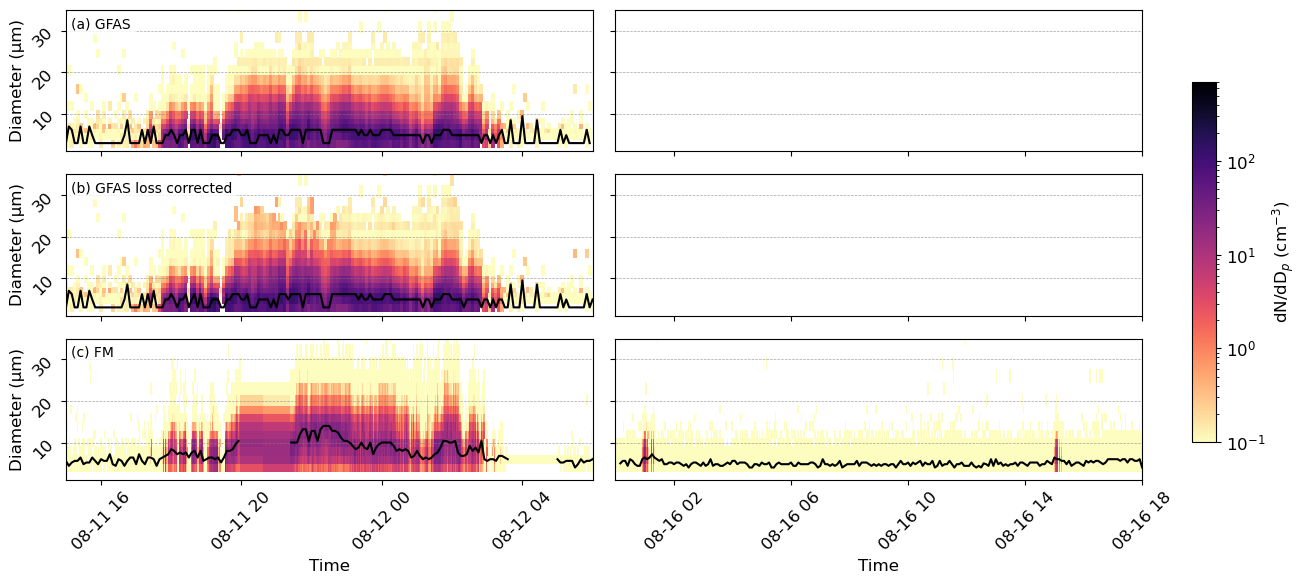

In [12]:
def is_number(x):
    try:
        float(x)
        return True
    except:
        return False

numeric_cols_gfas = [c for c in gfas_uncorrected.columns if is_number(c)]
numeric_cols_fm = [c for c in fm.columns if is_number(c)]

x = gfas_uncorrected.loc[start:end2].astype('float').astype(float).index
y = (gfas_uncorrected.loc[start:end2,numeric_cols_gfas].columns.astype('float').values)
z = gfas_uncorrected.loc[start:end2,numeric_cols_gfas].astype('float').values 
Z = z.T
X,Y = np.meshgrid(x,y)

a = gfas_loss_corrected.loc[start:end2].astype('float').astype(float).index
b = (gfas_loss_corrected.loc[start:end2,numeric_cols_gfas].columns.astype('float').values)
p = gfas_loss_corrected.loc[start:end2,numeric_cols_gfas].astype('float').values 
A,B = np.meshgrid(a,b)
C = p.T

d = fm.loc[start:end2].astype('float').astype(float).index
e = (fm.loc[start:end2,numeric_cols_fm].columns.astype('float').values)*10**6
f = fm.loc[start:end2,numeric_cols_fm].astype('float').values 
D,E = np.meshgrid(d,e)
F = f.T

vmin = 10**(-1)
vmax = 700

mode_gfas = (gfas_uncorrected.loc[start:end2,numeric_cols_gfas].idxmax(axis=1)).astype(float)
mode_gfas = mode_gfas.resample('5min').mean()
mode_fm = (fm.loc[start:end2,numeric_cols_fm].idxmax(axis=1)).astype(float)
mode_fm = (mode_fm.resample('5min').mean())*10**6
mode_corrected = (gfas_loss_corrected.loc[start:end2,numeric_cols_gfas].idxmax(axis=1)).astype(float)
mode_corrected = mode_corrected.resample('5min').mean()

#--------------------------------------------

fig, ax = plt.subplots(3,2, figsize=(12,6), sharey = True)
ax = ax.flatten()
x = ax[0].pcolor(X,Y,Z, norm = colors.LogNorm(vmin=vmin,vmax=vmax),cmap='magma_r', ) #vmin=10**(-2),vmax=10**3
a = ax[2].pcolor(A,B,C, norm = colors.LogNorm(vmin=vmin,vmax=vmax),cmap='magma_r', ) #vmin=10**(-2),vmax=10**3
d = ax[4].pcolor(D,E,F, norm = colors.LogNorm(vmin=vmin,vmax=vmax),cmap='magma_r', ) #vmin=10**(-2),vmax=10**3

x = ax[0+1].pcolor(X,Y,Z, norm = colors.LogNorm(vmin=vmin,vmax=vmax),cmap='magma_r', ) #vmin=10**(-2),vmax=10**3
a = ax[2+1].pcolor(A,B,C, norm = colors.LogNorm(vmin=vmin,vmax=vmax),cmap='magma_r', ) #vmin=10**(-2),vmax=10**3
d = ax[4+1].pcolor(D,E,F, norm = colors.LogNorm(vmin=vmin,vmax=vmax),cmap='magma_r', ) #vmin=10**(-2),vmax=10**3

ax[0].plot(mode_gfas, color = 'k', label = 'mode')
ax[2].plot(mode_corrected, color = 'k')
ax[4].plot(mode_fm, color = 'k')

ax[0+1].plot(mode_gfas, color = 'k', label = 'mode')
ax[2+1].plot(mode_corrected, color = 'k')
ax[4+1].plot(mode_fm, color = 'k')

# one colorbar for all three subplots
cbar = fig.colorbar(x, orientation='vertical', cax = fig.add_axes([1,0.25,0.02,0.6])) # [(position:) left, bottom, (size:) width, height]
cbar.set_label('dN/dD$_p$ (cm$^{-3}$)', fontsize=12)

ax[0].set(ylabel = 'Diameter (µm)',ylim = (1, 35))
ax[2].set(ylabel = 'Diameter (µm)', )
ax[4].set(xlabel = 'Time', ylabel = 'Diameter (µm)')

ax[0+1].set(ylim = (1, 35))
ax[2+1].set( )
ax[4+1].set(xlabel = 'Time')
# format x-axis as date
for axs in ax:       
    axs.tick_params(axis='both',which='major', rotation = 45)
    axs.xaxis.set_major_locator(mdates.HourLocator(interval=4))
    myFmt = mdates.DateFormatter('%m-%d %H')
    axs.xaxis.set_major_formatter(myFmt)
    axs.set_yticks([10, 20, 30,])
    axs.grid(which = 'major', axis = 'y', color='gray', linestyle='--', linewidth=0.5, alpha=0.7)
for i in range(4):
    ax[i].set_xticklabels([])

# add panel labels with a white background
names = ['(a) GFAS', '(b) GFAS loss corrected', '(c) FM']
for i, name in enumerate(names):
    ax[i*2].text(0.01, 0.95, name, transform=ax[i*2].transAxes, fontsize=10, va='top', ha='left', 
               bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='none'))
    ax[i*2].set(xlim = (start,end))
    ax[i*2+1].set(xlim = (start2,end2))

#ax[0].legend2(loc = 'upper right')        
plt.tight_layout()
fig.savefig(f'SizeDistribution_all', dpi=300, bbox_inches='tight')